In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.frameon': False})
NAT = 'blue'
MAN = 'red'
NEU = 'green'
FIG = 'figures'
os.makedirs(FIG, exist_ok=True)

def save(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [2]:

candidates = []
try:
    from google.colab import drive
    drive.mount('/content/drive')
    candidates.append('/content/drive/MyDrive/DATA 490-Capstone Project')
except Exception:
    pass
candidates += ['/content', '.', 'data']

raw_files = None
for d in candidates:
    a = sorted(glob.glob(os.path.join(d, 'USGS_Earthquakes_2000_2002*.csv')))
    b = sorted(glob.glob(os.path.join(d, 'USGS_Earthquakes_2003_2005*.csv')))
    if a and b:
        raw_files = [a[0], b[0]]
        break

if raw_files is None:
    raise FileNotFoundError('Put USGS_Earthquakes_2000_2002.csv and USGS_Earthquakes_2003_2005.csv '
                            'in the Drive folder DATA 490-Capstone Project, or in the same folder as this notebook.')
print('Using these files:')
for f in raw_files:
    print('  ', f)

Mounted at /content/drive
Using these files:
   /content/drive/MyDrive/DATA 490-Capstone Project/USGS_Earthquakes_2000_2002.csv
   /content/drive/MyDrive/DATA 490-Capstone Project/USGS_Earthquakes_2003_2005.csv


In [3]:

parts = [pd.read_csv(f, low_memory=False) for f in raw_files]
for f, p in zip(raw_files, parts):
    print(os.path.basename(f), 'rows:', p.shape[0], 'columns:', p.shape[1])

raw = pd.concat(parts, ignore_index=True)
raw['time'] = pd.to_datetime(raw['time'], utc=True)
n_rows = len(raw)
print('\nCombined rows:', n_rows, ' columns:', raw.shape[1])
print('Date range:', raw['time'].min(), 'to', raw['time'].max())
print('Duplicate rows:', raw.duplicated().sum(), ' Duplicate ids:', raw['id'].duplicated().sum())
print('Columns:', list(raw.columns))

USGS_Earthquakes_2000_2002.csv rows: 17251 columns: 22
USGS_Earthquakes_2003_2005.csv rows: 15930 columns: 22

Combined rows: 33181  columns: 22
Date range: 2000-01-01 00:20:00.020000+00:00 to 2005-12-31 23:59:05.583000+00:00
Duplicate rows: 0  Duplicate ids: 0
Columns: ['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource']


In [4]:

miss = raw.isnull().sum()
miss = miss[miss > 0].to_frame('missing_rows')
miss['percent_missing'] = (miss['missing_rows'] / n_rows * 100).round(1)
print(miss.sort_values('missing_rows', ascending=False))

                 missing_rows  percent_missing
magError                 9517             28.7
horizontalError          6203             18.7
dmin                     4688             14.1
magNst                   4501             13.6
depthError               3159              9.5
gap                      2029              6.1
rms                       175              0.5
nst                        52              0.2


In [5]:

print(raw['type'].value_counts())
raw['is_manmade'] = (raw['type'] != 'earthquake').astype(int)
print('\nHuman caused share of all rows:', round(raw['is_manmade'].mean() * 100, 1), 'percent')

qual = ['nst', 'gap', 'dmin', 'rms', 'horizontalError', 'depthError', 'magError', 'magNst']
share = raw.groupby('is_manmade')[qual].apply(lambda g: g.isnull().mean() * 100).round(1)
share.index = ['earthquake', 'human caused']
print('\nPercent missing, by event type')
print(share.T)
print('\nNetwork (net) by event type')
print(pd.crosstab(raw['net'], raw['is_manmade']).rename(columns={0: 'earthquake', 1: 'human caused'}))

type
earthquake            30440
explosion              1979
quarry blast            718
rock burst               36
sonic boom                5
chemical explosion        3
Name: count, dtype: int64

Human caused share of all rows: 8.3 percent

Percent missing, by event type
                 earthquake  human caused
nst                     0.2           0.0
gap                     1.0          63.0
dmin                    8.8          73.1
rms                     0.6           0.0
horizontalError        13.6          74.9
depthError              3.7          74.6
magError               24.4          76.2
magNst                  8.4          71.2

Network (net) by event type
is_manmade  earthquake  human caused
net                                 
ci               11611           406
nc               14118           320
nn                2248             2
rusms                0          1920
us                 644            32
uu                1624             0
uw                 19

In [6]:

raw['year'] = raw['time'].dt.year
raw['month'] = raw['time'].dt.month
raw['hour'] = raw['time'].dt.hour

drop_cols = ['id', 'updated', 'status', 'locationSource', 'magSource',
             'nst', 'gap', 'dmin', 'rms', 'horizontalError', 'depthError', 'magError', 'magNst']
eda_df = raw.drop(columns=drop_cols)
model_df = eda_df[['latitude', 'longitude', 'mag', 'year', 'month', 'hour', 'depth', 'is_manmade']].copy()


assert len(eda_df) == n_rows and len(model_df) == n_rows
assert model_df.isnull().sum().sum() == 0

eda_df.to_csv('seismic_eda_table.csv', index=False)
model_df.to_csv('seismic_model_table.csv', index=False)
print('seismic_eda_table.csv   :', eda_df.shape)
print('seismic_model_table.csv :', model_df.shape)
print('Missing values in model table:', int(model_df.isnull().sum().sum()))
model_df.head()

seismic_eda_table.csv   : (33181, 13)
seismic_model_table.csv : (33181, 8)
Missing values in model table: 0


,latitude,longitude,mag,year,month,hour,depth,is_manmade
0,31.768000,-116.634167,2.54,2002,12,23,8.161,0
1,39.002667,-111.317333,2.11,2002,12,23,2.470,0
2,31.755667,-116.655000,2.70,2002,12,22,5.281,0
3,33.186167,-115.611000,2.18,2002,12,21,1.673,0
4,43.549000,-105.240000,3.20,2002,12,21,0.000,1


In [7]:

print('Depth below zero:', int((model_df['depth'] < 0).sum()))
print('Depth exactly zero:', int((model_df['depth'] == 0).sum()))
print('Depth over 50 km:', int((model_df['depth'] > 50).sum()))
print('Depth over 100 km:', int((model_df['depth'] > 100).sum()))
print('Magnitude range:', model_df['mag'].min(), 'to', model_df['mag'].max())
print('\nLargest events')
print(eda_df.sort_values('mag', ascending=False).head(5)[['time', 'mag', 'depth', 'place', 'type']].to_string())
print('\nDepths over 100 km')
print(eda_df[eda_df['depth'] > 100][['depth', 'mag', 'place', 'type']].to_string())

Depth below zero: 1972
Depth exactly zero: 2333
Depth over 50 km: 11
Depth over 100 km: 2
Magnitude range: 2.0 to 7.2

Largest events
                                  time   mag   depth                                  place        type
19783 2005-06-15 02:50:54.190000+00:00  7.20  16.000     153 km W of Big Lagoon, California  earthquake
19675 2005-06-17 06:21:42.590000+00:00  6.60  12.000       196 km W of Ferndale, California  earthquake
29386 2003-12-22 19:15:56.240000+00:00  6.50   8.382     10 km NE of San Simeon, California  earthquake
32211 2003-03-12 23:41:32.920000+00:00  6.40  10.000   87 km SW of Paredón Colorado, Mexico  earthquake
23202 2004-09-28 17:15:24.250000+00:00  5.97   8.136  2004 Parkfield, California Earthquake  earthquake

Depths over 100 km
       depth  mag                              place        type
8568   131.3  2.1        32 km S of Kingston, Nevada   explosion
23271  227.4  2.3  8 km NNE of Pinion Pines, Arizona  earthquake


In [8]:
print(model_df.describe().T.round(2))
nat = model_df[model_df['is_manmade'] == 0]
man = model_df[model_df['is_manmade'] == 1]
print('\nEarthquakes:', len(nat), ' Human caused:', len(man))
summ = pd.DataFrame({
    'eq_mean': nat[['mag', 'depth', 'latitude', 'longitude', 'hour']].mean(),
    'eq_median': nat[['mag', 'depth', 'latitude', 'longitude', 'hour']].median(),
    'hc_mean': man[['mag', 'depth', 'latitude', 'longitude', 'hour']].mean(),
    'hc_median': man[['mag', 'depth', 'latitude', 'longitude', 'hour']].median()}).round(2)
print('\nBy event type (eq = earthquake, hc = human caused)')
print(summ)
print('\nEvents per year by type')
yr = model_df.groupby(['year', 'is_manmade']).size().unstack(fill_value=0)
yr.columns = ['earthquake', 'human_caused']
yr['total'] = yr.sum(axis=1)
yr['hc_percent'] = (yr['human_caused'] / yr['total'] * 100).round(1)
print(yr)

              count     mean   std      min      25%      50%      75%  \
latitude    33181.0    36.70  3.00    26.34    34.56    36.08    38.80   
longitude   33181.0  -118.18  4.26  -127.09  -121.10  -118.61  -116.18   
mag         33181.0     2.45  0.45     2.00     2.12     2.30     2.64   
year        33181.0  2002.37  1.70  2000.00  2001.00  2002.00  2004.00   
month       33181.0     6.43  3.60     1.00     3.00     6.00    10.00   
hour        33181.0    12.15  7.19     0.00     6.00    13.00    19.00   
depth       33181.0     6.07  5.84    -3.49     2.34     5.19     7.78   
is_manmade  33181.0     0.08  0.28     0.00     0.00     0.00     0.00   

                max  
latitude      44.90  
longitude   -103.61  
mag            7.20  
year        2005.00  
month         12.00  
hour          23.00  
depth        227.40  
is_manmade     1.00  

Earthquakes: 30440  Human caused: 2741

By event type (eq = earthquake, hc = human caused)
           eq_mean  eq_median  hc_mean  hc_

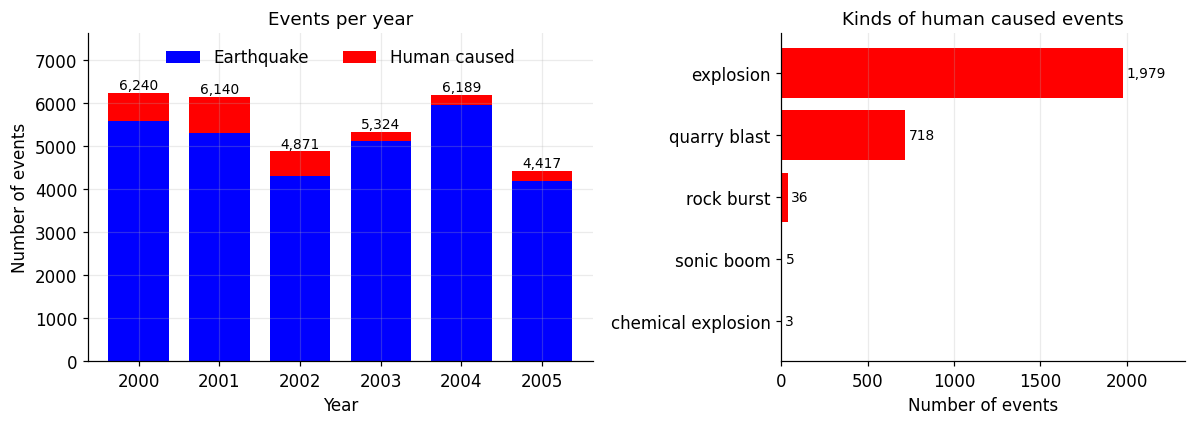

type
explosion             1979
quarry blast           718
rock burst              36
sonic boom               5
chemical explosion       3
Name: count, dtype: int64


In [9]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1.25, 1]})
yr[['earthquake', 'human_caused']].plot(kind='bar', stacked=True, color=[NAT, MAN], ax=ax[0], width=0.75, legend=False)
for i, (t, h) in enumerate(zip(yr['total'], yr['human_caused'])):
    ax[0].text(i, t + 80, f'{t:,}', ha='center', fontsize=9)
ax[0].set_xticklabels(yr.index, rotation=0)
ax[0].set_xlabel('Year'); ax[0].set_ylabel('Number of events')
ax[0].set_title('Events per year'); ax[0].set_ylim(0, yr['total'].max() * 1.22)
ax[0].legend(['Earthquake', 'Human caused'], loc='upper center', ncol=2)

tc = eda_df.loc[eda_df['is_manmade'] == 1, 'type'].value_counts()
ax[1].barh(tc.index[::-1], tc.values[::-1], color=MAN)
for i, v in enumerate(tc.values[::-1]):
    ax[1].text(v + 20, i, f'{v:,}', va='center', fontsize=9)
ax[1].set_xlim(0, tc.max() * 1.18)
ax[1].set_xlabel('Number of events'); ax[1].set_title('Kinds of human caused events')
ax[1].grid(axis='y', alpha=0)
plt.tight_layout(); save('fig01_events_per_year')
print(tc)

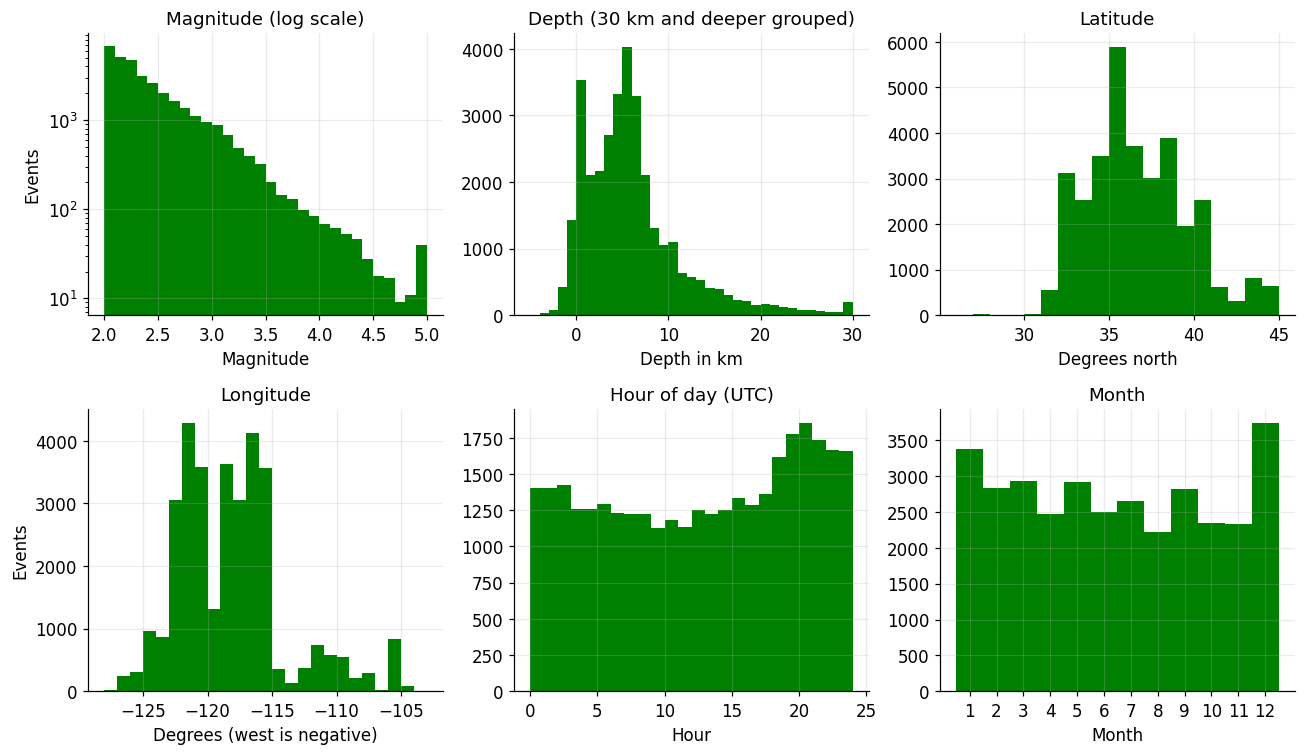

Skew of depth: 3.73  Skew of magnitude: 1.83
Share of events under magnitude 3: 87.6 percent
Share of events at magnitude 4 or more: 1.2 percent
Share of events 15 km or shallower: 92.9 percent
Events per month: [3379, 2836, 2929, 2470, 2926, 2505, 2657, 2225, 2826, 2351, 2332, 3745]
December by year: {2000: 508, 2001: 493, 2002: 374, 2003: 1697, 2004: 367, 2005: 306}


In [10]:

fig, ax = plt.subplots(2, 3, figsize=(12, 7))
ax = ax.ravel()
ax[0].hist(np.clip(model_df['mag'], 2, 5), bins=np.arange(2, 5.1, 0.1), color=NEU)
ax[0].set_yscale('log'); ax[0].set_title('Magnitude (log scale)'); ax[0].set_xlabel('Magnitude'); ax[0].set_ylabel('Events')
ax[1].hist(np.clip(model_df['depth'], -5, 30), bins=np.arange(-5, 31, 1), color=NEU)
ax[1].set_title('Depth (30 km and deeper grouped)'); ax[1].set_xlabel('Depth in km')
ax[2].hist(model_df['latitude'], bins=np.arange(26, 46, 1), color=NEU)
ax[2].set_title('Latitude'); ax[2].set_xlabel('Degrees north')
ax[3].hist(model_df['longitude'], bins=np.arange(-128, -102, 1), color=NEU)
ax[3].set_title('Longitude'); ax[3].set_xlabel('Degrees (west is negative)'); ax[3].set_ylabel('Events')
ax[4].hist(model_df['hour'], bins=np.arange(0, 25, 1), color=NEU)
ax[4].set_title('Hour of day (UTC)'); ax[4].set_xlabel('Hour')
ax[5].hist(model_df['month'], bins=np.arange(0.5, 13.5, 1), color=NEU)
ax[5].set_title('Month'); ax[5].set_xlabel('Month'); ax[5].set_xticks(range(1, 13))
plt.tight_layout(); save('fig02_distributions')
print('Skew of depth:', round(stats.skew(model_df['depth']), 2), ' Skew of magnitude:', round(stats.skew(model_df['mag']), 2))
print('Share of events under magnitude 3:', round((model_df['mag'] < 3).mean() * 100, 1), 'percent')
print('Share of events at magnitude 4 or more:', round((model_df['mag'] >= 4).mean() * 100, 2), 'percent')
print('Share of events 15 km or shallower:', round((model_df['depth'] <= 15).mean() * 100, 1), 'percent')
print('Events per month:', model_df.groupby('month').size().tolist())
print('December by year:', model_df[model_df['month'] == 12].groupby('year').size().to_dict())

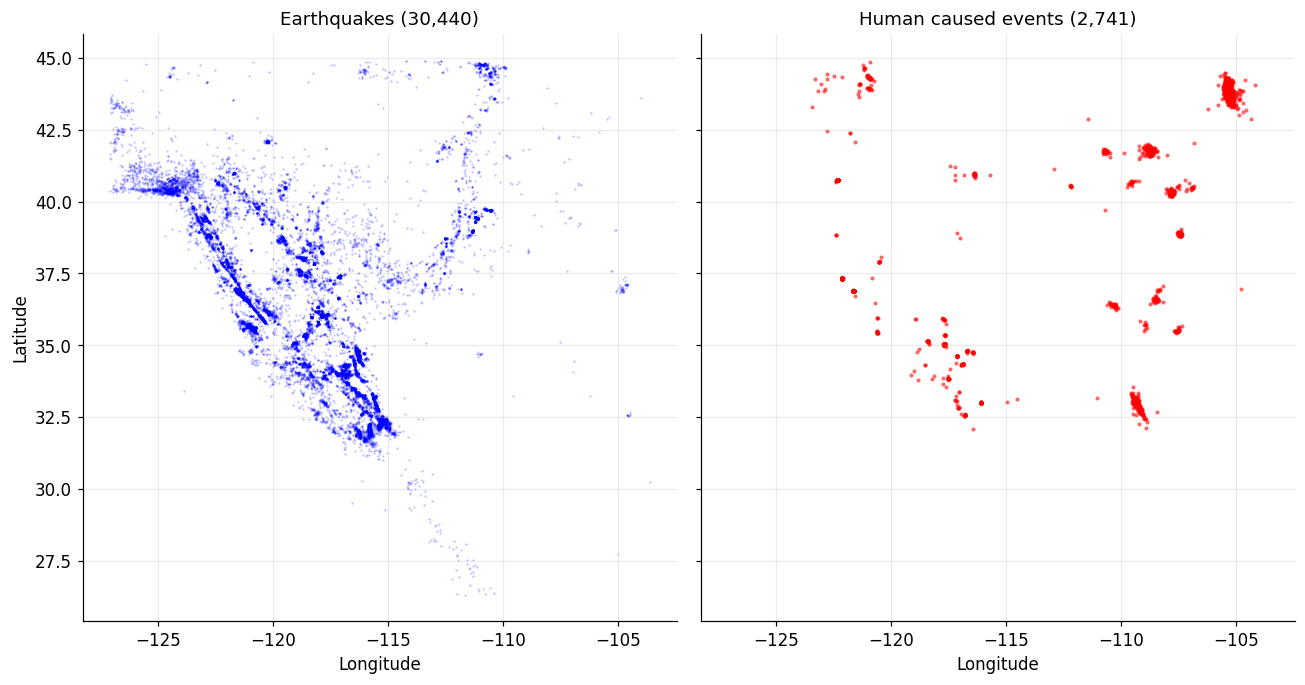

Latitude range: 26.335 to 44.9
Longitude range: -127.09 to -103.612
Mean longitude, earthquakes: -118.8  human caused: -110.9
Share of human caused events east of longitude -114: 70.4 percent
Share of earthquakes east of longitude -114: 6.2 percent


In [11]:

fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
ax[0].scatter(nat['longitude'], nat['latitude'], s=2, alpha=0.25, color=NAT, linewidths=0)
ax[0].set_title(f'Earthquakes ({len(nat):,})')
ax[1].scatter(man['longitude'], man['latitude'], s=7, alpha=0.6, color=MAN, linewidths=0)
ax[1].set_title(f'Human caused events ({len(man):,})')
for a in ax:
    a.set_xlabel('Longitude'); a.set_aspect(1.25)
ax[0].set_ylabel('Latitude')
plt.tight_layout(); save('fig03_maps')
print('Latitude range:', model_df['latitude'].min(), 'to', model_df['latitude'].max())
print('Longitude range:', model_df['longitude'].min(), 'to', model_df['longitude'].max())
print('Mean longitude, earthquakes:', round(nat['longitude'].mean(), 1), ' human caused:', round(man['longitude'].mean(), 1))
print('Share of human caused events east of longitude -114:', round((man['longitude'] > -114).mean() * 100, 1), 'percent')
print('Share of earthquakes east of longitude -114:', round((nat['longitude'] > -114).mean() * 100, 1), 'percent')

In [12]:

def get_state(p):
    s = str(p).split(',')[-1].strip()
    for key, name in [('New Mexico', 'New Mexico'), ('NM', 'New Mexico'), ('California', 'California'), ('CA', 'California'),
                      ('Nevada', 'Nevada'), ('NV', 'Nevada'), ('Utah', 'Utah'), ('UT', 'Utah'),
                      ('Wyoming', 'Wyoming'), ('WY', 'Wyoming'), ('Arizona', 'Arizona'), ('AZ', 'Arizona'),
                      ('Oregon', 'Oregon'), ('OR', 'Oregon'), ('Colorado', 'Colorado'), ('CO', 'Colorado'),
                      ('Montana', 'Montana'), ('MT', 'Montana'), ('Idaho', 'Idaho'), ('ID', 'Idaho'),
                      ('Washington', 'Washington'), ('WA', 'Washington'),
                      ('Mexico', 'Mexico'), ('MX', 'Mexico'), ('B.C.', 'Mexico')]:
        if (len(key) > 2 and key in s) or s == key:
            return name
    return 'Other'
eda_df['state'] = eda_df['place'].apply(get_state)
print(eda_df['state'].value_counts())
print('\nExamples of Other:', eda_df.loc[eda_df['state'] == 'Other', 'place'].head(8).tolist())

state
California    24281
Mexico         2817
Nevada         1849
Utah           1230
Wyoming        1208
Arizona         576
Oregon          415
Colorado        335
Montana         240
Idaho           136
New Mexico       93
Other             1
Name: count, dtype: int64

Examples of Other: ['13 km SSE of Alpine, Texas']


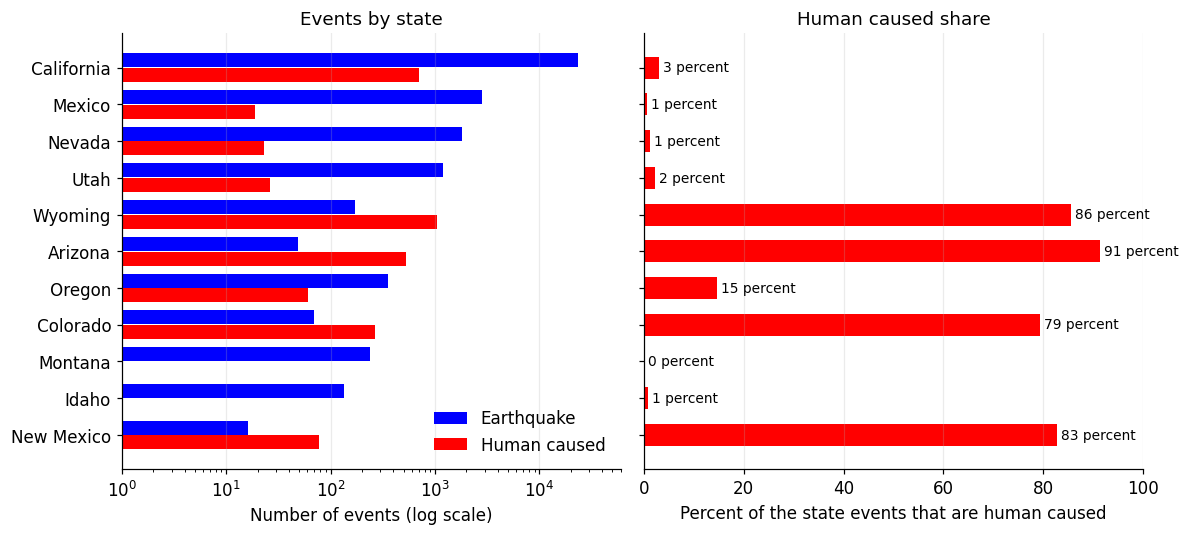

            earthquake  human_caused  total  hc_percent
state                                                  
California       23575           706  24281         2.9
Mexico            2798            19   2817         0.7
Nevada            1826            23   1849         1.2
Utah              1204            26   1230         2.1
Wyoming            173          1035   1208        85.7
Arizona             49           527    576        91.5
Oregon             354            61    415        14.7
Colorado            69           266    335        79.4
Montana            240             0    240         0.0
Idaho              135             1    136         0.7
New Mexico          16            77     93        82.8

Human caused events by state
state
Wyoming       1035
California     706
Arizona        527
Colorado       266
New Mexico      77
Oregon          61
Utah            26
Nevada          23
Mexico          19
Idaho            1
Name: count, dtype: int64
state
Wyoming       

In [14]:

st = eda_df.groupby(['state', 'is_manmade']).size().unstack(fill_value=0)
st.columns = ['earthquake', 'human_caused']
st['total'] = st.sum(axis=1)
st['hc_percent'] = st['human_caused'] / st['total'] * 100
st = st[st.index != 'Other'].sort_values('total')
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
y = np.arange(len(st))
ax[0].barh(y + 0.2, st['earthquake'].clip(lower=0.8), height=0.38, color=NAT, label='Earthquake')
ax[0].barh(y - 0.2, st['human_caused'].clip(lower=0.8), height=0.38, color=MAN, label='Human caused')
ax[0].set_xscale('log'); ax[0].set_xlim(1, 60000)
ax[0].set_yticks(y); ax[0].set_yticklabels(st.index)
ax[0].set_xlabel('Number of events (log scale)'); ax[0].set_title('Events by state'); ax[0].legend(loc='lower right')
ax[1].barh(y, st['hc_percent'], height=0.6, color=MAN)
for i, v in enumerate(st['hc_percent']):
    ax[1].text(v + 0.8, i, f'{v:.0f} percent', va='center', fontsize=9)
ax[1].set_xlim(0, 100); ax[1].set_xlabel('Percent of the state events that are human caused'); ax[1].set_title('Human caused share')
ax[0].grid(axis='y', alpha=0); ax[1].grid(axis='y', alpha=0)
plt.tight_layout(); save('fig04_states')
print(st.sort_values('total', ascending=False).round(1))
mmst = eda_df[eda_df['is_manmade'] == 1]['state'].value_counts()
print('\nHuman caused events by state'); print(mmst)
print((mmst / mmst.sum() * 100).round(1).head(5))

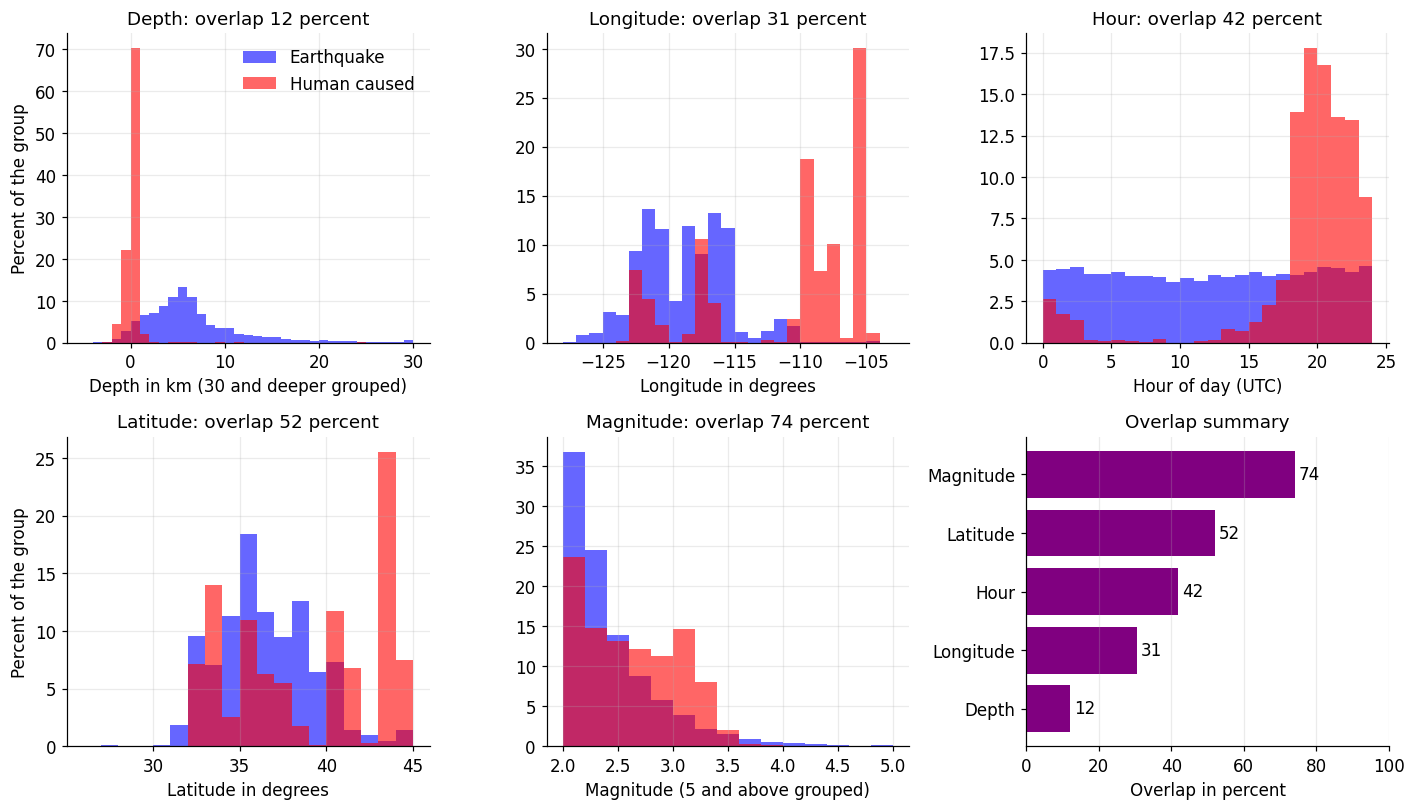

           overlap_percent  ks_distance
Depth                 12.0         0.91
Longitude             31.0         0.68
Hour                  42.0         0.58
Latitude              52.0         0.41
Magnitude             74.0         0.29


In [16]:

specs = {
    'Depth': ('depth', -5, 30, 1, 'Depth in km (30 and deeper grouped)'),
    'Longitude': ('longitude', -128, -103, 1, 'Longitude in degrees'),
    'Hour': ('hour', 0, 24, 1, 'Hour of day (UTC)'),
    'Latitude': ('latitude', 26, 45, 1, 'Latitude in degrees'),
    'Magnitude': ('mag', 2, 5, 0.2, 'Magnitude (5 and above grouped)')}

def shares(x, lo, hi, w):
    edges = np.arange(lo, hi + w / 2, w)
    c, _ = np.histogram(np.clip(x, lo, hi - 1e-9), bins=edges)
    return edges, c / c.sum()

overlap, ks = {}, {}
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))
ax = ax.ravel()
for i, (name, (col, lo, hi, w, lab)) in enumerate(specs.items()):
    edges, pn = shares(nat[col], lo, hi, w)
    _, pm = shares(man[col], lo, hi, w)
    overlap[name] = np.minimum(pn, pm).sum() * 100
    ks[name] = stats.ks_2samp(nat[col], man[col]).statistic
    ax[i].bar(edges[:-1], pn * 100, width=w, align='edge', color=NAT, alpha=0.6, label='Earthquake')
    ax[i].bar(edges[:-1], pm * 100, width=w, align='edge', color=MAN, alpha=0.6, label='Human caused')
    ax[i].set_title(f'{name}: overlap {overlap[name]:.0f} percent')
    ax[i].set_xlabel(lab)
    if i % 3 == 0: ax[i].set_ylabel('Percent of the group')
ax[0].legend()
ov = pd.Series(overlap).sort_values()
ax[5].barh(ov.index, ov.values, color='purple')
for j, v in enumerate(ov.values):
    ax[5].text(v + 1, j, f'{v:.0f}', va='center')
ax[5].set_xlim(0, 100); ax[5].set_xlabel('Overlap in percent'); ax[5].set_title('Overlap summary')
ax[5].grid(axis='y', alpha=0)
plt.tight_layout(); save('fig05_overlap_histograms')
tab = pd.DataFrame({'overlap_percent': pd.Series(overlap).round(0), 'ks_distance': pd.Series(ks).round(2)}).sort_values('overlap_percent')
print(tab)

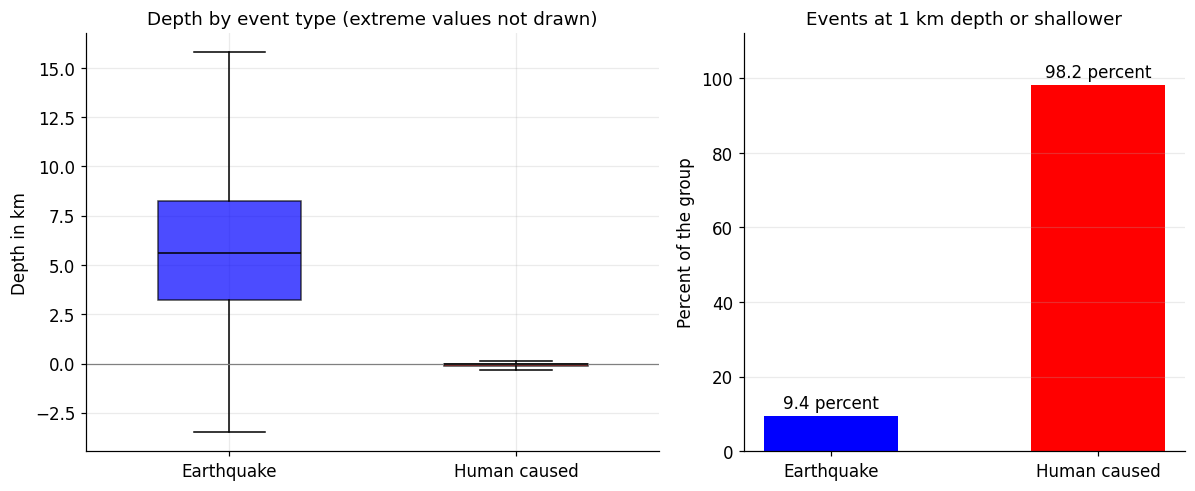

Median depth: earthquakes 5.62  human caused 0.0
Q1 and Q3 earthquakes: [3.22, 8.25]  human caused: [-0.14, 0.0]
Share at 1 km or shallower: earthquakes 9.4  human caused 98.2
Share exactly 0 km: earthquakes 1.4  human caused 70.0
Mann Whitney U test on depth: statistic 3934499.5  p value 0.0


In [17]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
bp = ax[0].boxplot([nat['depth'], man['depth']], tick_labels=['Earthquake', 'Human caused'], showfliers=False,
                   patch_artist=True, widths=0.5, medianprops={'color': 'black'})
for patch, c in zip(bp['boxes'], [NAT, MAN]):
    patch.set_facecolor(c); patch.set_alpha(0.7)
ax[0].set_ylabel('Depth in km'); ax[0].set_title('Depth by event type (extreme values not drawn)')
ax[0].axhline(0, color='gray', lw=0.8)
sh = pd.Series({'Earthquake': (nat['depth'] <= 1).mean() * 100, 'Human caused': (man['depth'] <= 1).mean() * 100})
ax[1].bar(sh.index, sh.values, color=[NAT, MAN], width=0.5)
for i, v in enumerate(sh.values):
    ax[1].text(i, v + 2, f'{v:.1f} percent', ha='center')
ax[1].set_ylim(0, 112); ax[1].set_ylabel('Percent of the group'); ax[1].set_title('Events at 1 km depth or shallower')
ax[1].grid(axis='x', alpha=0)
plt.tight_layout(); save('fig06_depth_by_type')
print('Median depth: earthquakes', round(nat['depth'].median(), 2), ' human caused', round(man['depth'].median(), 2))
print('Q1 and Q3 earthquakes:', nat['depth'].quantile([.25, .75]).round(2).tolist(), ' human caused:', man['depth'].quantile([.25, .75]).round(2).tolist())
print('Share at 1 km or shallower: earthquakes', round(sh['Earthquake'], 1), ' human caused', round(sh['Human caused'], 1))
print('Share exactly 0 km: earthquakes', round((nat['depth'] == 0).mean() * 100, 1), ' human caused', round((man['depth'] == 0).mean() * 100, 1))
u = stats.mannwhitneyu(man['depth'], nat['depth'])
print('Mann Whitney U test on depth: statistic', u.statistic, ' p value', u.pvalue)

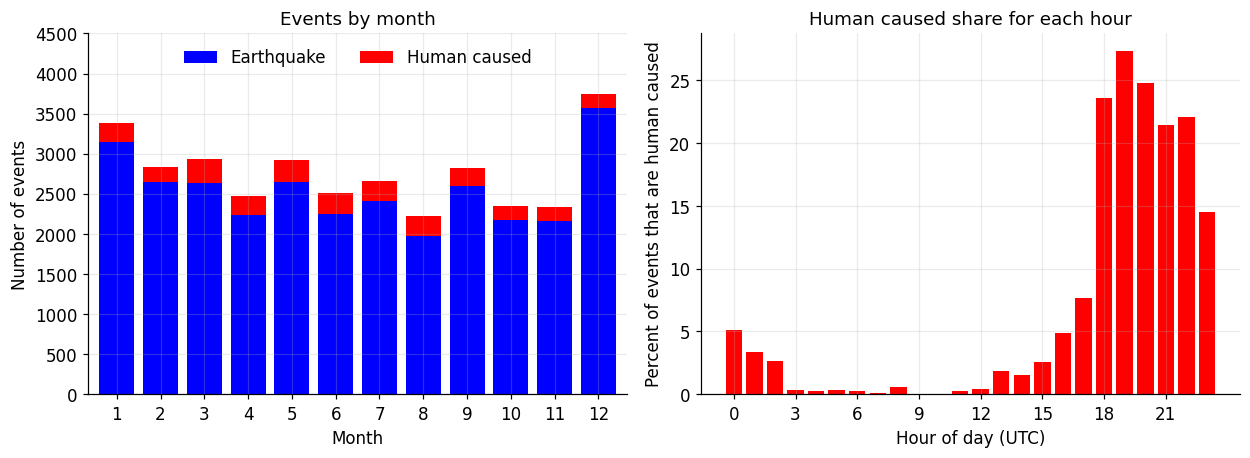

Human caused percent by hour:
{0: 5.1, 1: 3.3, 2: 2.7, 3: 0.3, 4: 0.2, 5: 0.3, 6: 0.2, 7: 0.1, 8: 0.6, 9: 0.0, 10: 0.0, 11: 0.3, 12: 0.4, 13: 1.9, 14: 1.5, 15: 2.6, 16: 4.9, 17: 7.6, 18: 23.6, 19: 27.4, 20: 24.8, 21: 21.5, 22: 22.1, 23: 14.5}
Share of human caused events between 18:00 and 23:59 UTC: 84.3 percent
Share of earthquakes between 18:00 and 23:59 UTC: 26.3 percent
Human caused events with hour 9 or 10: 0
Human caused by net and year:
net    ci  nc  nn  rusms  us  uw
year                            
2000  101  17   0    532   0   7
2001  121  55   2    649   2   2
2002   71  53   0    423  13  12
2003   33  55   0    107   3  16
2004   43  71   0    104   6  13
2005   37  69   0    105   8  11


In [18]:

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
mo = model_df.groupby(['month', 'is_manmade']).size().unstack(fill_value=0)
mo.columns = ['Earthquake', 'Human caused']
mo.plot(kind='bar', stacked=True, color=[NAT, MAN], ax=ax[0], width=0.8)
ax[0].set_xticklabels(range(1, 13), rotation=0); ax[0].set_xlabel('Month'); ax[0].set_ylabel('Number of events')
ax[0].set_title('Events by month'); ax[0].set_ylim(0, 4500); ax[0].legend(loc='upper center', ncol=2)
hr = model_df.groupby('hour')['is_manmade'].mean() * 100
ax[1].bar(hr.index, hr.values, color=MAN)
ax[1].set_xlabel('Hour of day (UTC)'); ax[1].set_ylabel('Percent of events that are human caused')
ax[1].set_title('Human caused share for each hour'); ax[1].set_xticks(range(0, 24, 3))
plt.tight_layout(); save('fig07_time_patterns')
print('Human caused percent by hour:'); print(hr.round(1).to_dict())
print('Share of human caused events between 18:00 and 23:59 UTC:', round(man['hour'].between(18, 23).mean() * 100, 1), 'percent')
print('Share of earthquakes between 18:00 and 23:59 UTC:', round(nat['hour'].between(18, 23).mean() * 100, 1), 'percent')
print('Human caused events with hour 9 or 10:', int(man['hour'].isin([9, 10]).sum()))
print('Human caused by net and year:')
print(pd.crosstab(eda_df.loc[eda_df['is_manmade'] == 1, 'year'], eda_df.loc[eda_df['is_manmade'] == 1, 'net']))

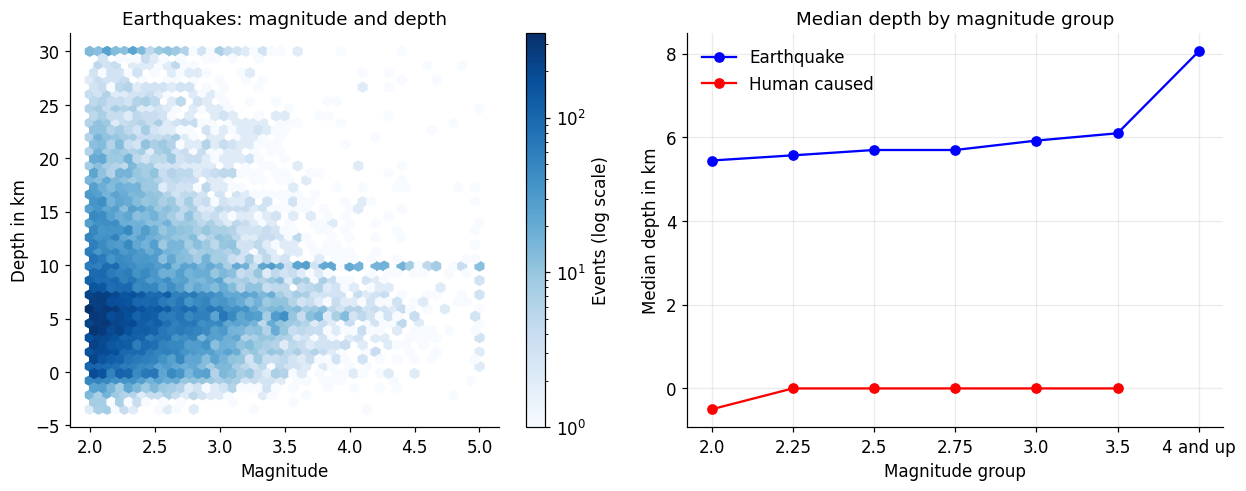

All events:    Spearman -0.004 p 0.44601987299494583 | Pearson 0.005 p 0.39376244391219933
Earthquakes:   Spearman 0.056 p 1.0199088887645853e-22
Human caused:  Spearman 0.612 p 3.910185711849143e-281
Earthquake
          median   size
b                      
2.0         5.45  13424
2.25        5.57   7252
2.5         5.70   4158
2.75        5.70   2337
3.0         5.92   2205
3.5         6.10    668
4 and up    8.06    396
Human caused
          median  size
b                     
2.0         -0.5   773
2.25         0.0   296
2.5          0.0   517
2.75         0.0   315
3.0          0.0   773
3.5          0.0    64
4 and up     0.0     3

Events with depth exactly 10 km: 303 of 33181 ( 0.9 percent )
Earthquakes with magnitude 2 to 3 : 27171 events, 0.1 percent at exactly 10 km
Earthquakes with magnitude 3 to 4 : 2873 events, 5.5 percent at exactly 10 km
Earthquakes with magnitude 4 to 5 : 361 events, 28.8 percent at exactly 10 km
Earthquakes with magnitude 5 to 8 : 35 events, 28.6 pe

In [19]:

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
hb = ax[0].hexbin(nat['mag'].clip(upper=5), nat['depth'].clip(-5, 30), gridsize=45, cmap='Blues', bins='log', mincnt=1)
plt.colorbar(hb, ax=ax[0], label='Events (log scale)')
ax[0].set_xlabel('Magnitude'); ax[0].set_ylabel('Depth in km'); ax[0].set_title('Earthquakes: magnitude and depth'); ax[0].grid(False)
bins = [2, 2.25, 2.5, 2.75, 3, 3.5, 4, 8]
labs = ['2.0', '2.25', '2.5', '2.75', '3.0', '3.5', '4 and up']
for grp, name, c in [(nat, 'Earthquake', NAT), (man, 'Human caused', MAN)]:
    g = grp.assign(b=pd.cut(grp['mag'], bins, right=False, labels=labs)).groupby('b', observed=True)['depth'].agg(['median', 'size'])
    g = g[g['size'] >= 20]
    ax[1].plot(g.index.astype(str), g['median'], marker='o', color=c, label=name)
ax[1].set_xlabel('Magnitude group'); ax[1].set_ylabel('Median depth in km'); ax[1].set_title('Median depth by magnitude group'); ax[1].legend()
plt.tight_layout(); save('fig08_magnitude_depth')
r1 = stats.spearmanr(model_df['mag'], model_df['depth'])
r2 = stats.spearmanr(nat['mag'], nat['depth'])
r3 = stats.spearmanr(man['mag'], man['depth'])
p1 = stats.pearsonr(model_df['mag'], model_df['depth'])
print('All events:    Spearman', round(r1.statistic, 3), 'p', r1.pvalue, '| Pearson', round(p1.statistic, 3), 'p', p1.pvalue)
print('Earthquakes:   Spearman', round(r2.statistic, 3), 'p', r2.pvalue)
print('Human caused:  Spearman', round(r3.statistic, 3), 'p', r3.pvalue)
for grp, name in [(nat, 'Earthquake'), (man, 'Human caused')]:
    g = grp.assign(b=pd.cut(grp['mag'], bins, right=False, labels=labs)).groupby('b', observed=True)['depth'].agg(['median', 'size'])
    print(name); print(g.round(2))
print('\nEvents with depth exactly 10 km:', int((model_df['depth'] == 10).sum()), 'of', len(model_df), '(', round((model_df['depth'] == 10).mean() * 100, 1), 'percent )')
for lo, hi in [(2, 3), (3, 4), (4, 5), (5, 8)]:
    g = nat[(nat['mag'] >= lo) & (nat['mag'] < hi)]
    print('Earthquakes with magnitude', lo, 'to', hi, ':', len(g), 'events,', round((g['depth'] == 10).mean() * 100, 1), 'percent at exactly 10 km')
print('\nHuman caused kinds: median depth and mean magnitude')
print(eda_df[eda_df['is_manmade'] == 1].groupby('type').agg(events=('depth', 'size'), median_depth=('depth', 'median'), mean_mag=('mag', 'mean')).round(2))

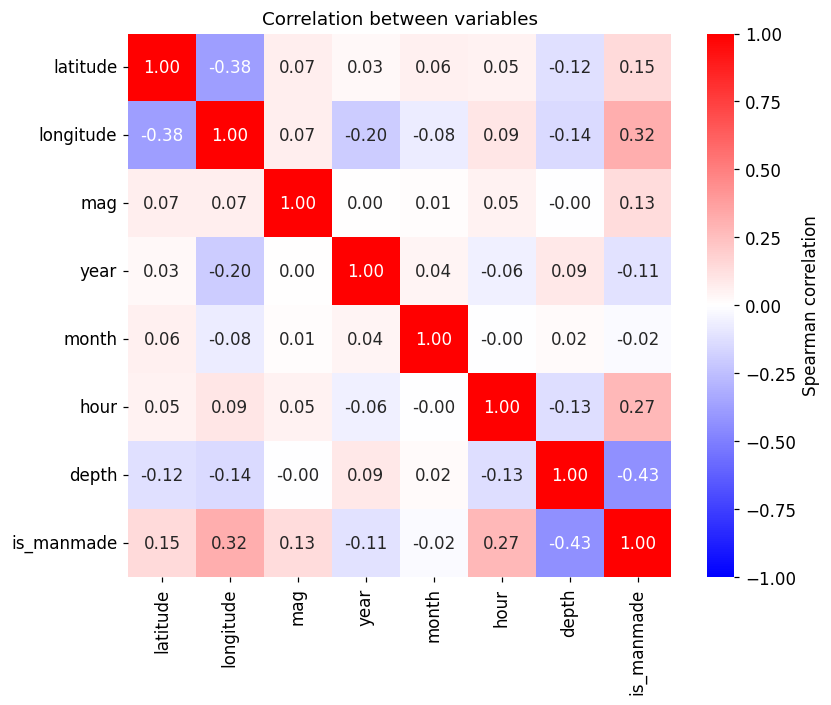

depth        -0.43
year         -0.11
month        -0.02
mag           0.13
latitude      0.15
hour          0.27
longitude     0.32
is_manmade    1.00
Name: is_manmade, dtype: float64
is_manmade   -0.43
longitude    -0.14
hour         -0.13
latitude     -0.12
mag          -0.00
month         0.02
year          0.09
depth         1.00
Name: depth, dtype: float64


In [20]:

cm = model_df.corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='bwr', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'label': 'Spearman correlation'})
plt.title('Correlation between variables'); plt.grid(False)
plt.tight_layout(); save('fig09_correlation')
print(cm['is_manmade'].round(2).sort_values())
print(cm['depth'].round(2).sort_values())